Estructura de la Parte 2 del proyecto
 Regresión Lineal Múltiple
Paso 1: Importación de librerías y carga del dataset
Aca cargamos los datos y hacemos la primera inspección rápida para verificar que no haya errores de lectura.

Dataset cargado desde local: 1338 filas x 7 columnas


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


,age,bmi,children,charges
count,1338.00,1338.00,1338.00,1338.00
mean,39.21,30.66,1.09,13270.42
std,14.05,6.10,1.21,12110.01
min,18.00,15.96,0.00,1121.87
25%,27.00,26.30,0.00,4740.29
50%,39.00,30.40,1.00,9382.03
75%,51.00,34.69,2.00,16639.91
max,64.00,53.13,5.00,63770.43


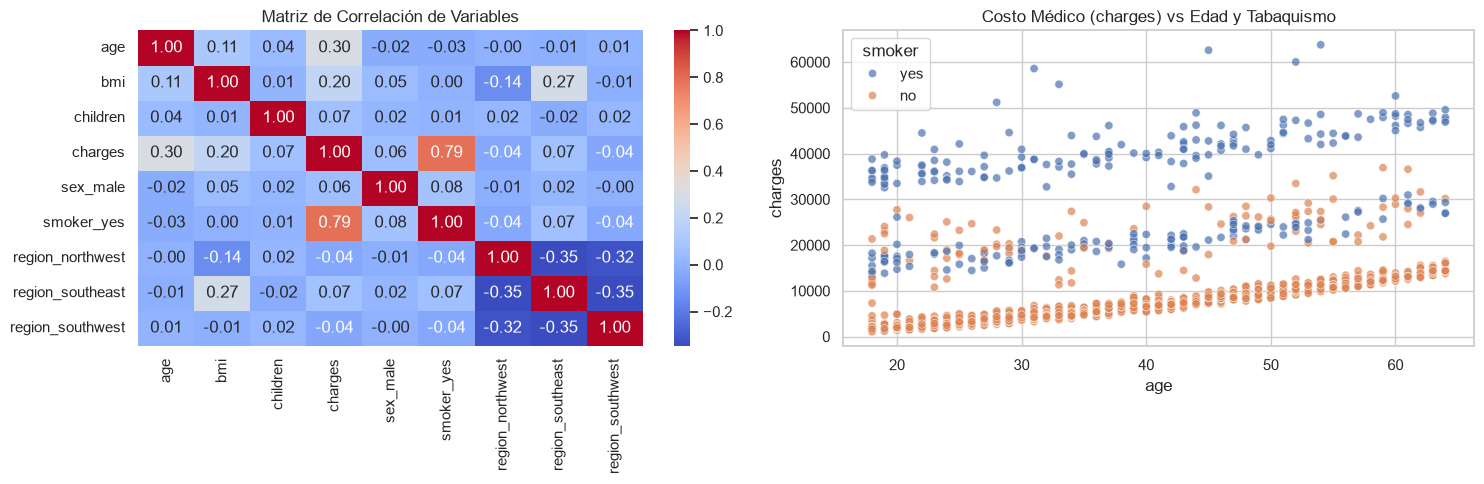

In [6]:
%matplotlib inline
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")

# 1. Carga de datos desde el archivo local
df = pd.read_csv("insurance.csv")

print(f"Dataset cargado desde local: {df.shape[0]} filas x {df.shape[1]} columnas")
display(df.head())
display(df.describe().round(2))

# Visualización de variables y correlaciones
df_encoded = pd.get_dummies(df, drop_first=True, dtype=int)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.heatmap(df_encoded.corr(), annot=True, cmap="coolwarm", fmt=".2f", ax=axes[0])
axes[0].set_title("Matriz de Correlación de Variables")

sns.scatterplot(data=df, x="age", y="charges", hue="smoker", alpha=0.7, ax=axes[1])
axes[1].set_title("Costo Médico (charges) vs Edad y Tabaquismo")

plt.tight_layout()
plt.show()

Celda 2: Análisis Exploratorio (EDA), Boxplots y Codificación (Encoding)
Revisamos valores nulos, detectamos posibles outliers con boxplots y transformamos las columnas de texto (sex, smoker, region) a variables numéricas (get_dummies) para analizar la matriz de correlación.

--- Valores Nulos por Columna ---
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64


,age,bmi,children,charges
count,1338.00,1338.00,1338.00,1338.00
mean,39.21,30.66,1.09,13270.42
std,14.05,6.10,1.21,12110.01
min,18.00,15.96,0.00,1121.87
25%,27.00,26.30,0.00,4740.29
50%,39.00,30.40,1.00,9382.03
75%,51.00,34.69,2.00,16639.91
max,64.00,53.13,5.00,63770.43


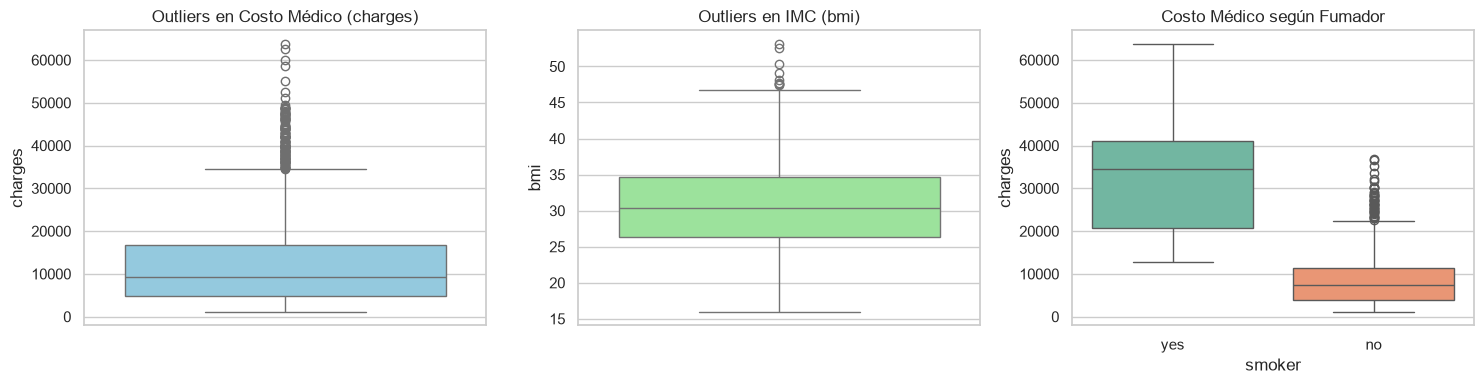

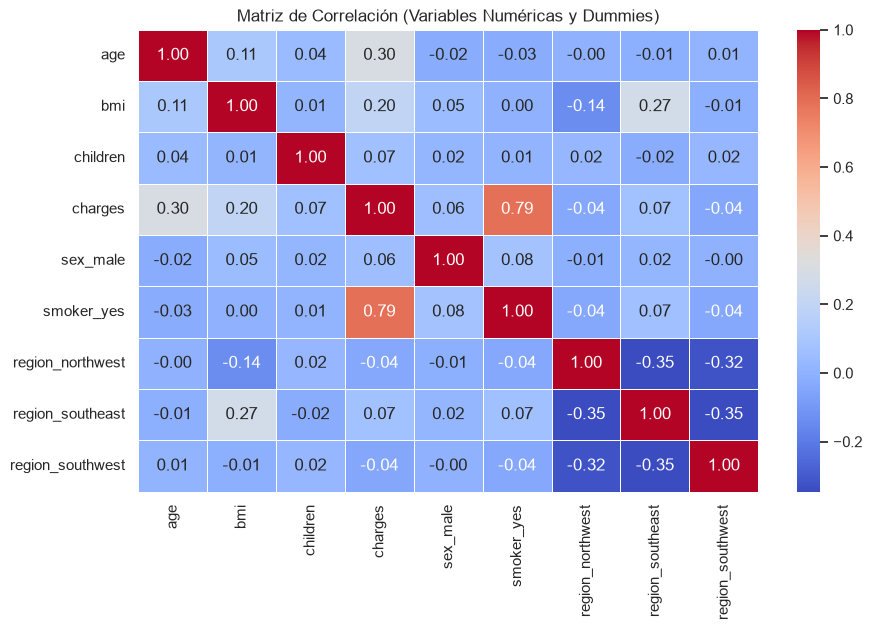

In [7]:
# 1. Revisión de tipos de datos y valores nulos
print("--- Valores Nulos por Columna ---")
print(df.isnull().sum())
display(df.describe().round(2))

# 2. Boxplots para detectar outliers en la variable objetivo y numéricas clave
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(y=df["charges"], ax=axes[0], color="skyblue")
axes[0].set_title("Outliers en Costo Médico (charges)")

sns.boxplot(y=df["bmi"], ax=axes[1], color="lightgreen")
axes[1].set_title("Outliers en IMC (bmi)")

sns.boxplot(x="smoker", y="charges" , hue="smoker", data=df, ax=axes[2], palette="Set2", legend=False)
axes[2].set_title("Costo Médico según Fumador")

plt.tight_layout()
plt.show()

# 3. Codificación One-Hot (drop_first=True evita multicolinealidad perfecta / trampa de variables dummy)
df_encoded = pd.get_dummies(df, drop_first=True, dtype=int)

# 4. Matriz de Correlación
plt.figure(figsize=(10, 6))
sns.heatmap(df_encoded.corr(), annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Matriz de Correlación (Variables Numéricas y Dummies)")
plt.show()

Celda 3: Definición de Variables ($X$ e $y$) y División Train / TestSeparamos las 8 variables predictoras ($X$) de la variable objetivo charges ($y$), reservando el 20% de los datos para evaluar el rendimiento real fuera de muestra.

In [8]:
X = df_encoded.drop(columns=["charges"])
y = df_encoded["charges"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print(f"Set de Entrenamiento (Train): {X_train.shape[0]} registros")
print(f"Set de Prueba (Test):         {X_test.shape[0]} registros")

Set de Entrenamiento (Train): 1070 registros
Set de Prueba (Test):         268 registros


Entrenamiento del Modelo e Interpretación de Coeficientes
Ajustamos la regresión lineal múltiple con X_train y ordenamos los coeficientes ($\beta$) de mayor a menor impacto en dólares.

In [9]:
modelo = LinearRegression()
modelo.fit(X_train, y_train)

print(f"Intercepto (b0 - costo base teórico): ${modelo.intercept_:,.2f}\n")

tabla_coef = pd.DataFrame({
    "Variable": X.columns,
    "Coeficiente (Impacto en USD)": modelo.coef_
}).sort_values(by="Coeficiente (Impacto en USD)", ascending=False)

display(tabla_coef.round(2))

Intercepto (b0 - costo base teórico): $-11,931.22



,Variable,Coeficiente (Impacto en USD)
4,smoker_yes,23651.13
2,children,425.28
1,bmi,337.09
0,age,256.98
3,sex_male,-18.59
5,region_northwest,-370.68
6,region_southeast,-657.86
7,region_southwest,-809.80


Evaluación Comparativa (Train vs. Test) — Chequeo de OverfittingCalculamos $R^2$, MAE y RMSE tanto en entrenamiento como en prueba para demostrar que el modelo generaliza bien y no memorizó los datos.Python

In [13]:
# Predicciones sobre ambos conjuntos
y_pred_train = modelo.predict(X_train)
y_pred_test = modelo.predict(X_test)

# Métricas en Train
r2_train = r2_score(y_train, y_pred_train)
rmse_train = np.sqrt(mean_squared_error(y_train, y_pred_train))

# Métricas en Test
r2_test = r2_score(y_test, y_pred_test)
mae_test = mean_absolute_error(y_test, y_pred_test)
rmse_test = np.sqrt(mean_squared_error(y_test, y_pred_test))

comparativa = pd.DataFrame({
    "Métrica": ["R² (Varianza Explicada)", "MAE (Error Absoluto Medio)", "RMSE (Raíz Error Cuadrático)"],
    "Entrenamiento (Train)": [f"{r2_train:.4f}", f"${mean_absolute_error(y_train, y_pred_train):,.2f}", f"${rmse_train:,.2f}"],
    "Prueba (Test)": [f"{r2_test:.4f}", f"${mae_test:,.2f}", f"${rmse_test:,.2f}"]
})

print("=== COMPARATIVA TRAIN VS. TEST ===")
display(comparativa)

=== COMPARATIVA TRAIN VS. TEST ===


,Métrica,Entrenamiento (Train),Prueba (Test)
0,R² (Varianza Explicada),0.7417,0.7836
1,MAE (Error Absoluto Medio),"$4,208.23","$4,181.19"
2,RMSE (Raíz Error Cuadrático),"$6,105.55","$5,796.28"


Diagnóstico Visual (Reales vs. Predichos, Homocedasticidad y Normalidad de Residuos)
Generamos tres gráficos en fila para evaluar visualmente la calidad del ajuste y los supuestos de los errores.

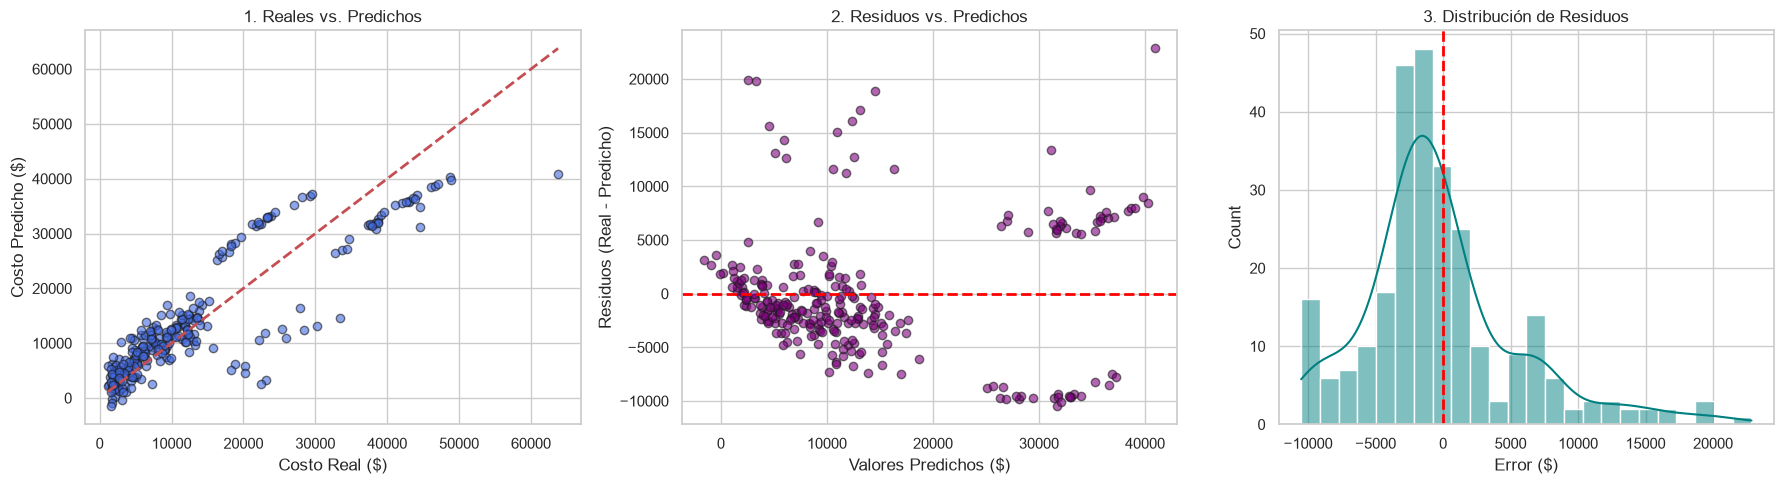

In [14]:
residuos = y_test - y_pred_test

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Valores Reales vs Predichos
axes[0].scatter(y_test, y_pred_test, alpha=0.6, color="royalblue", edgecolors="k")
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--", lw=2)
axes[0].set_xlabel("Costo Real ($)")
axes[0].set_ylabel("Costo Predicho ($)")
axes[0].set_title("1. Reales vs. Predichos")

# 2. Residuos vs Predicciones (Chequeo de Homocedasticidad)
axes[1].scatter(y_pred_test, residuos, alpha=0.6, color="purple", edgecolors="k")
axes[1].axhline(0, color="red", linestyle="--", lw=2)
axes[1].set_xlabel("Valores Predichos ($)")
axes[1].set_ylabel("Residuos (Real - Predicho)")
axes[1].set_title("2. Residuos vs. Predichos")

# 3. Distribución de los Residuos (Chequeo de Normalidad)
sns.histplot(residuos, kde=True, ax=axes[2], color="teal")
axes[2].axvline(0, color="red", linestyle="--", lw=2)
axes[2].set_xlabel("Error ($)")
axes[2].set_title("3. Distribución de Residuos")

plt.tight_layout()
plt.show()

📈 Conclusiones del Modelo de Regresión Lineal Múltiple
¿Cuál fue el desempeño del modelo?
El modelo logró un desempeño sólido y consistente para una regresión lineal base, alcanzando un coeficiente de determinación $R^2 = 0.7836$ (78.36%) en el conjunto de prueba, con un MAE de $4.181,19 y un RMSE de $5.796,28. Esto indica que el modelo logra explicar casi el 80% de la variabilidad del costo anual del seguro médico a partir de las variables disponibles.

¿Qué variable fue la más influyente según los coeficientes del modelo?
La variable más influyente por amplio margen fue smoker_yes (condición de fumador), con un coeficiente positivo de +$23.651,13. Esto demuestra que, manteniendo constantes el resto de las variables (ceteris paribus), ser fumador incrementa el costo anual estimado del seguro en más de $23.650 USD. Le siguen en importancia el índice de masa corporal (bmi, +$337,09 por unidad) y la edad (age, +$256,98 por año).

¿Las features extraídas del dataset fueron buenas predictoras o se sugieren otras?
Las variables extraídas (smoker, age, bmi, children, sex, region) demostraron ser buenas predictoras globales (explicando el 78.36% de la varianza), destacando las variables clínicas y demográficas por sobre la ubicación geográfica (region), cuyo impacto en el costo es marginal. Como mejora futura, se sugiere incorporar términos de interacción (como smoker_yes * bmi, dado que la combinación de obesidad y tabaquismo dispara los costos de forma no lineal) y sumar variables clínicas adicionales como historial de enfermedades crónicas, presión arterial o nivel de actividad física.